In [1]:
import torch
import shap
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
import sys
import os

project_root = os.path.abspath("..")
sys.path.append(project_root)

In [3]:
from src.explainability import explain_prediction
from src.model import FaultDiagnosisNet

In [4]:
input_size = 72
num_classes = 6

model = FaultDiagnosisNet(input_size, num_classes)

In [5]:
model.load_state_dict(torch.load("C:/Users/hp/predictive-maintenance-diagnosis/models/fault_diagnosis_model.pth"))
scaler = joblib.load("C:/Users/hp/predictive-maintenance-diagnosis/models/scaler.pkl")
le = joblib.load("C:/Users/hp/predictive-maintenance-diagnosis/models/label_encoder.pkl")

In [6]:
df = pd.read_csv("C:/Users/hp/predictive-maintenance-diagnosis/data/processed/mafaulda_features_FINAL.csv")

# 2. Prepare X and y
X = df.drop(columns=["fault_type", "file_id"])
y = df["fault_type"]
groups = df["file_id"]

# 3. Group split (same as training)
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(gss.split(X, y, groups))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]


In [7]:
scaler = joblib.load("../models/scaler.pkl")

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)


## model in evaluation mode

In [8]:
model.eval()

FaultDiagnosisNet(
  (network): Sequential(
    (0): Linear(in_features=72, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): ReLU()
    (10): Linear(in_features=16, out_features=6, bias=True)
  )
)

In [6]:
import os
# run this in a cell to see what's actually in the file right now
with open('../src/model.py', 'r') as f:
    print(f.read())

import torch.nn as nn

class FaultDiagnosisNet(nn.Module):
    def __init__(self, input_size, num_classes, dropout_rate=0.3):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, num_classes)
        )

    def forward(self, x):
        return self.network(x)


## Background dataset

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

background = torch.tensor(
    X_train_scaled[:100],
    dtype=torch.float32
).to(device)

In [10]:
# Create the explainer
explainer = shap.DeepExplainer(model, background)


## Calculer les SHAP values

In [11]:
np.random.seed(42)
random_idx = np.random.choice(len(X_test_scaled), size=200, replace=False)

sample_to_explain = torch.tensor(X_test_scaled[random_idx], dtype=torch.float32).to(device)
shap_values = explainer.shap_values(sample_to_explain)

print(type(shap_values))
if isinstance(shap_values, list):
    print(f"{len(shap_values)} classes, each shape: {shap_values[0].shape}")
else:
    print(shap_values.shape)

<class 'numpy.ndarray'>
(200, 72, 6)


## Summary plot

C:\Users\hp\AppData\Local\Temp\ipykernel_61696\2779256032.py:7: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


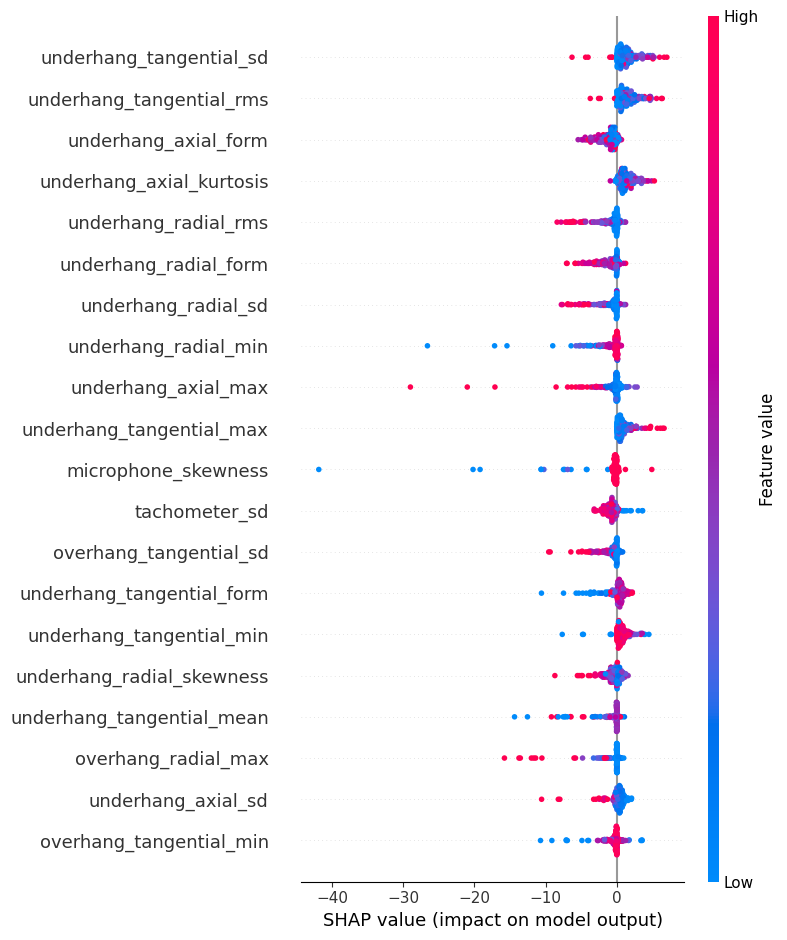

In [12]:

X_test_sample_df = X_test.iloc[random_idx].reset_index(drop=True)
y_test_sample = y_test.iloc[random_idx].reset_index(drop=True)
feature_cols = list(X_train.columns) 

class_idx = 0  # e.g. explain feature importance for class le.classes_[0]

shap.summary_plot(
    shap_values[:, :, class_idx],
    X_test_sample_df,
    feature_names=feature_cols
)


--- SHAP summary for class: horizontal_misalignment ---


C:\Users\hp\AppData\Local\Temp\ipykernel_61696\2435549122.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


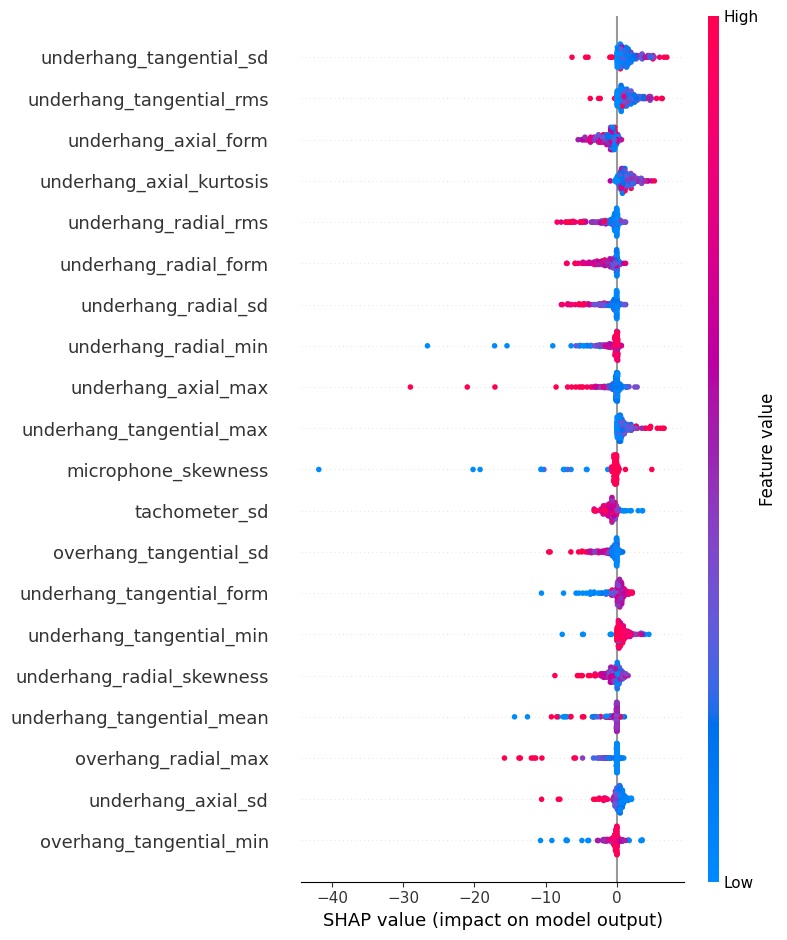


--- SHAP summary for class: imbalance ---


C:\Users\hp\AppData\Local\Temp\ipykernel_61696\2435549122.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


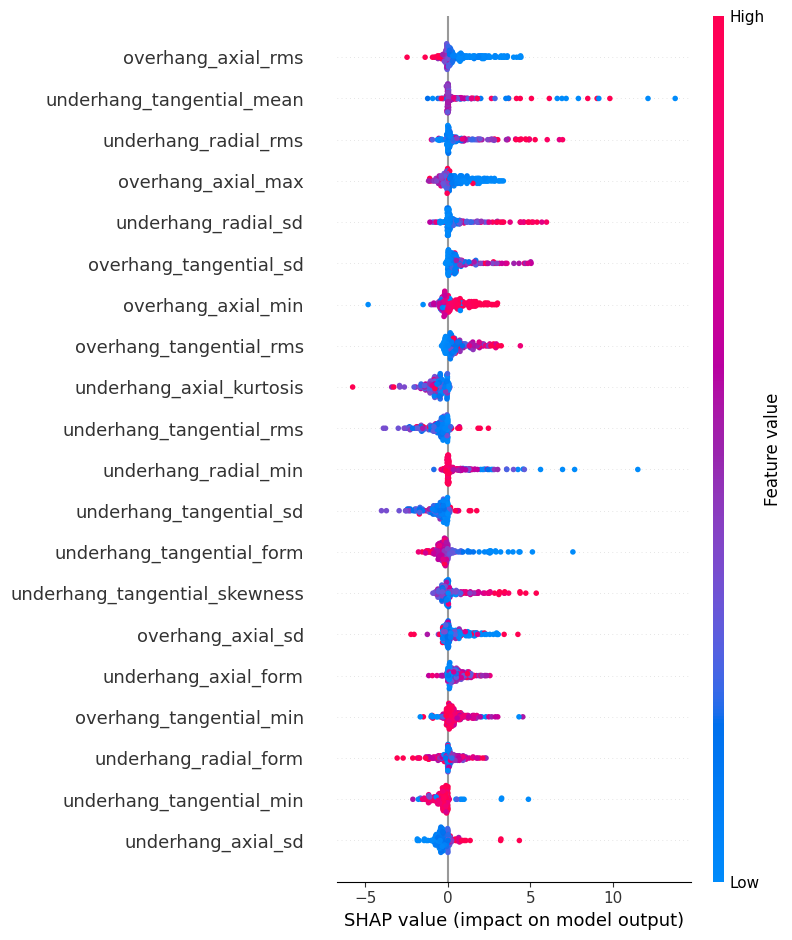


--- SHAP summary for class: normal ---


C:\Users\hp\AppData\Local\Temp\ipykernel_61696\2435549122.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


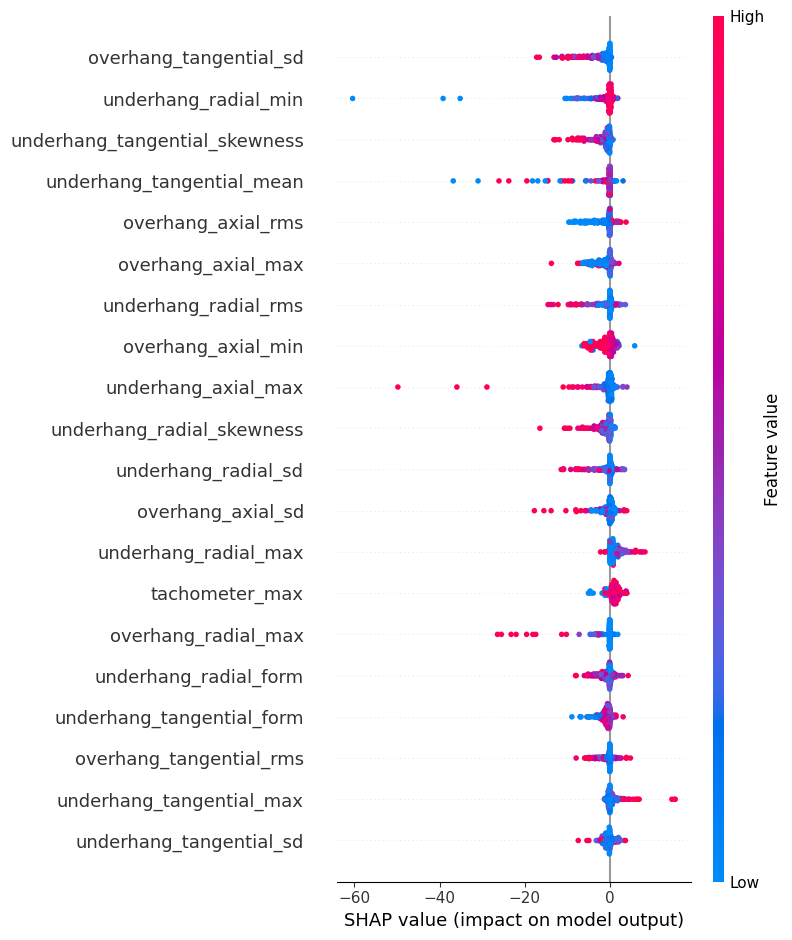


--- SHAP summary for class: overhang_bearing ---


C:\Users\hp\AppData\Local\Temp\ipykernel_61696\2435549122.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


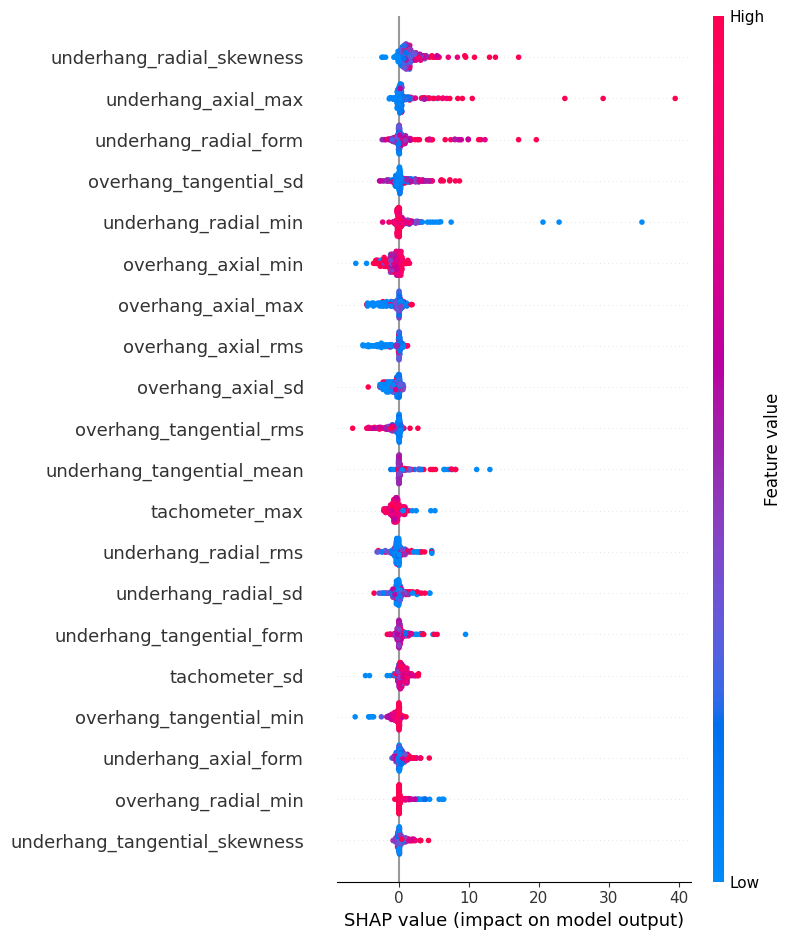


--- SHAP summary for class: underhang_bearing ---


C:\Users\hp\AppData\Local\Temp\ipykernel_61696\2435549122.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


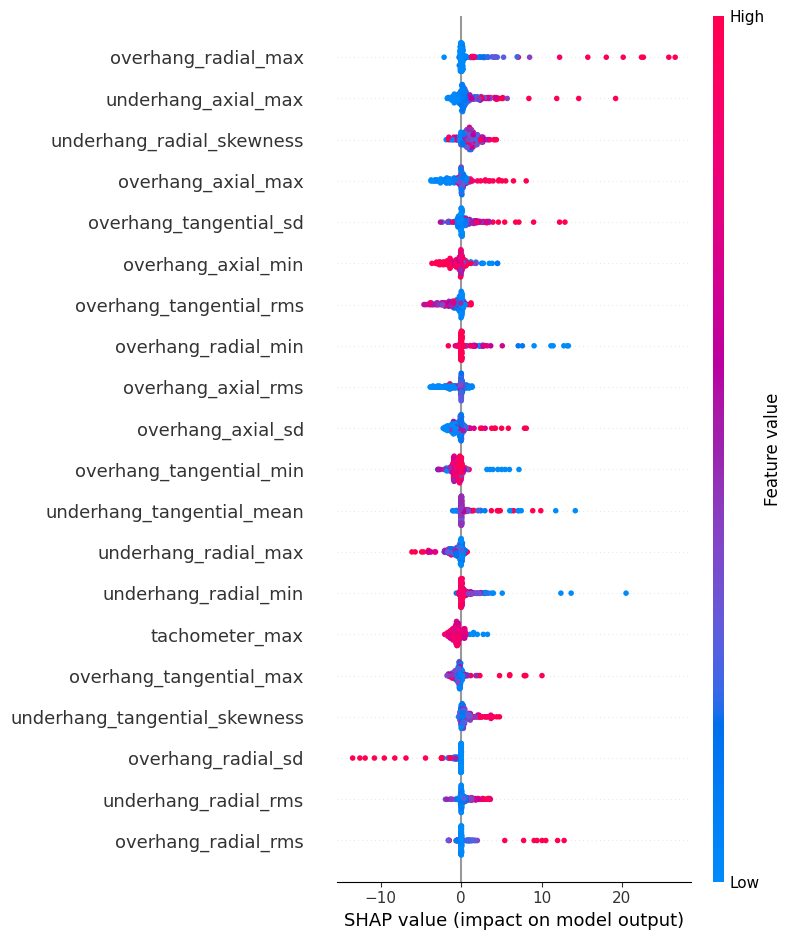


--- SHAP summary for class: vertical_misalignment ---


C:\Users\hp\AppData\Local\Temp\ipykernel_61696\2435549122.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


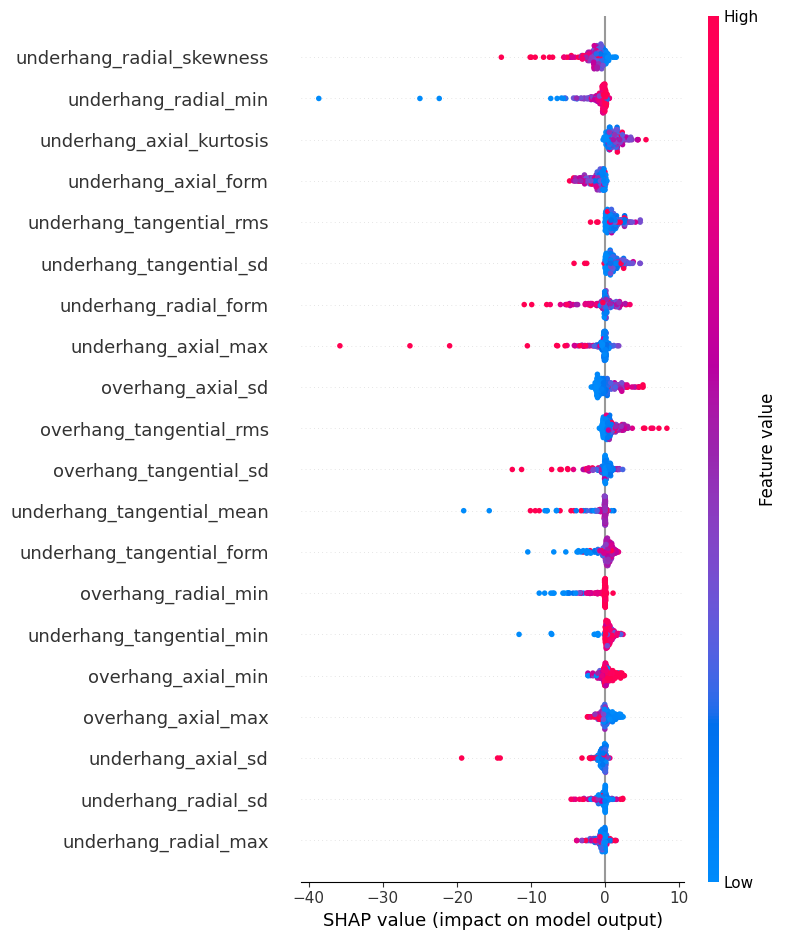

In [13]:
for class_idx in range(len(le.classes_)):
    print(f"\n--- SHAP summary for class: {le.classes_[class_idx]} ---")
    shap.summary_plot(
        shap_values[:, :, class_idx],
        X_test_sample_df,
        feature_names=feature_cols,
        show=True
    )

## Local explanation

In [14]:
shap_values = explainer.shap_values(sample_to_explain)
print(shap_values.shape)  # should still be (200, 72, 6)

(200, 72, 6)


In [15]:
print(type(shap_values))
if isinstance(shap_values, list):
    print("List of length:", len(shap_values))
    print("Each element shape:", shap_values[0].shape)
else:
    print("Array shape:", shap_values.shape)

<class 'numpy.ndarray'>
Array shape: (200, 72, 6)


Vraie classe: normal
Classe prédite: underhang_bearing


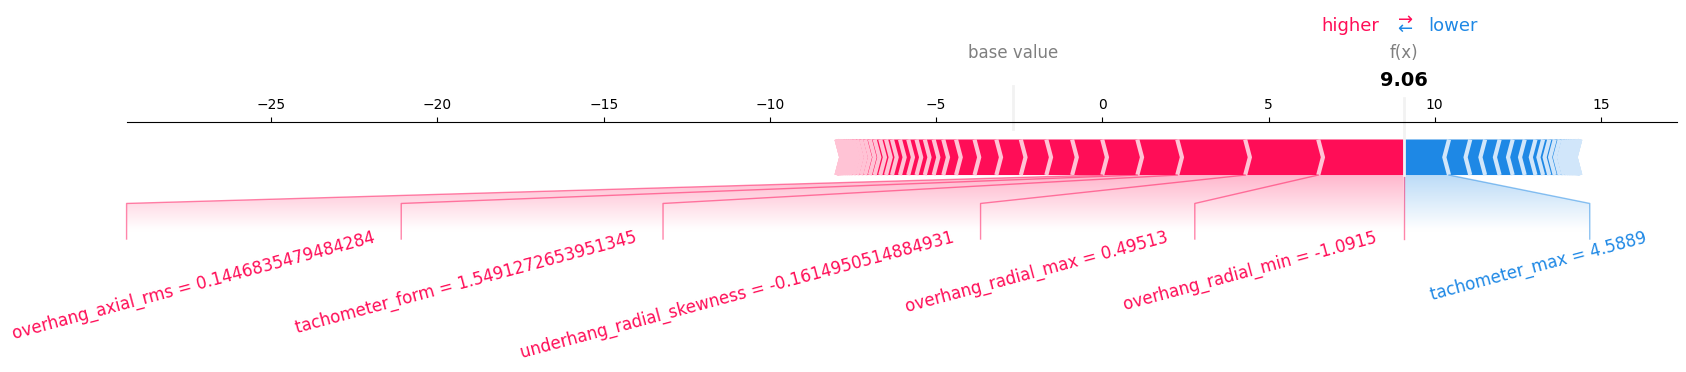

In [16]:
idx = 0

pred_output = model(sample_to_explain[idx:idx+1]).detach().cpu().numpy()
pred_class_idx = np.argmax(pred_output)

print(f"Vraie classe: {y_test.iloc[idx]}")
print(f"Classe prédite: {le.classes_[pred_class_idx]}")

shap.force_plot(
    explainer.expected_value[pred_class_idx],
    shap_values[idx, :, pred_class_idx],
    X_test_sample_df.iloc[idx],
    matplotlib=True,
    text_rotation=15  # helps spread labels out a bit
)

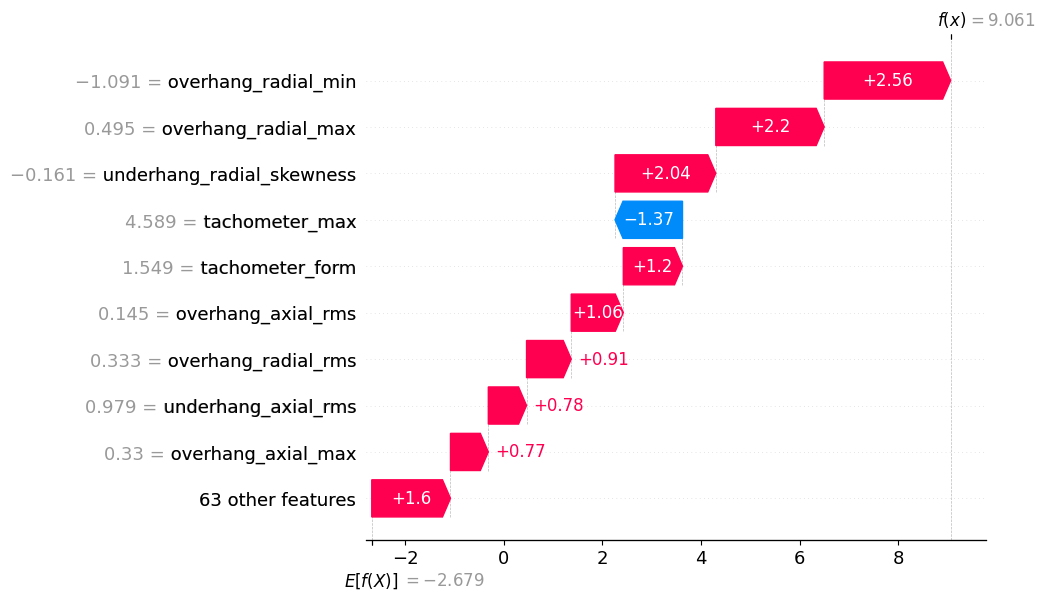

In [17]:
shap_explanation = shap.Explanation(
    values=shap_values[idx, :, pred_class_idx],
    base_values=explainer.expected_value[pred_class_idx],
    data=X_test_sample_df.iloc[idx].values,
    feature_names=feature_cols
)

shap.plots.waterfall(shap_explanation, max_display=10)

In [18]:
preds = np.argmax(model(sample_to_explain).detach().cpu().numpy(), axis=1)
true_labels = y_test_sample.values

correct_mask = (preds == le.transform(true_labels))

examples = {}
for class_idx, class_name in enumerate(le.classes_):
    class_correct_idxs = np.where(correct_mask & (preds == class_idx))[0]
    if len(class_correct_idxs) > 0:
        examples[class_name] = class_correct_idxs[0]

print(examples)

{'horizontal_misalignment': 9, 'imbalance': 4, 'normal': 2, 'overhang_bearing': 1, 'underhang_bearing': 0, 'vertical_misalignment': 7}



=== Sample 2 — True: normal, Predicted: normal ===


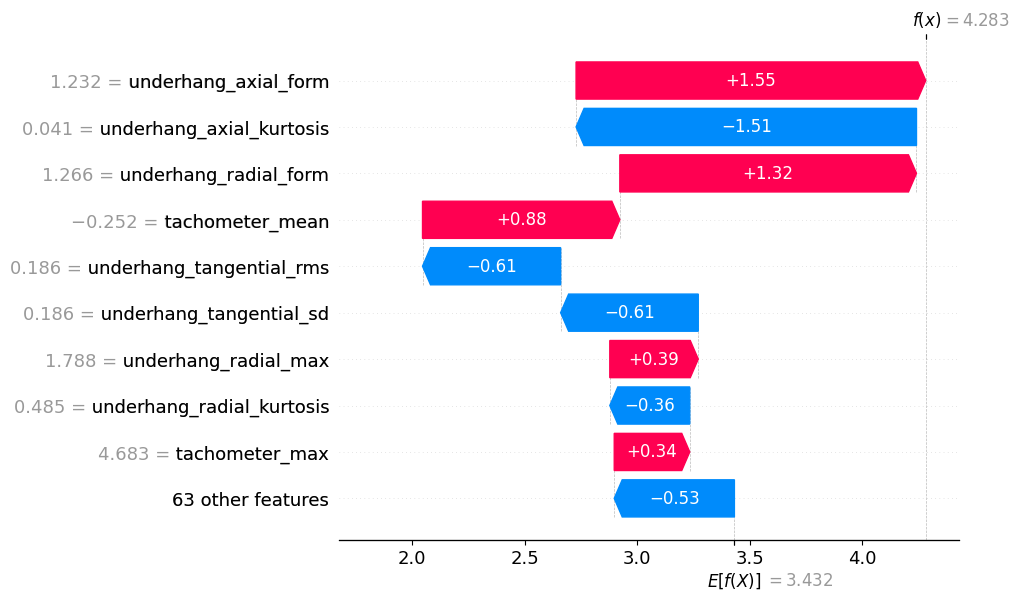


=== Sample 0 — True: normal, Predicted: underhang_bearing ===


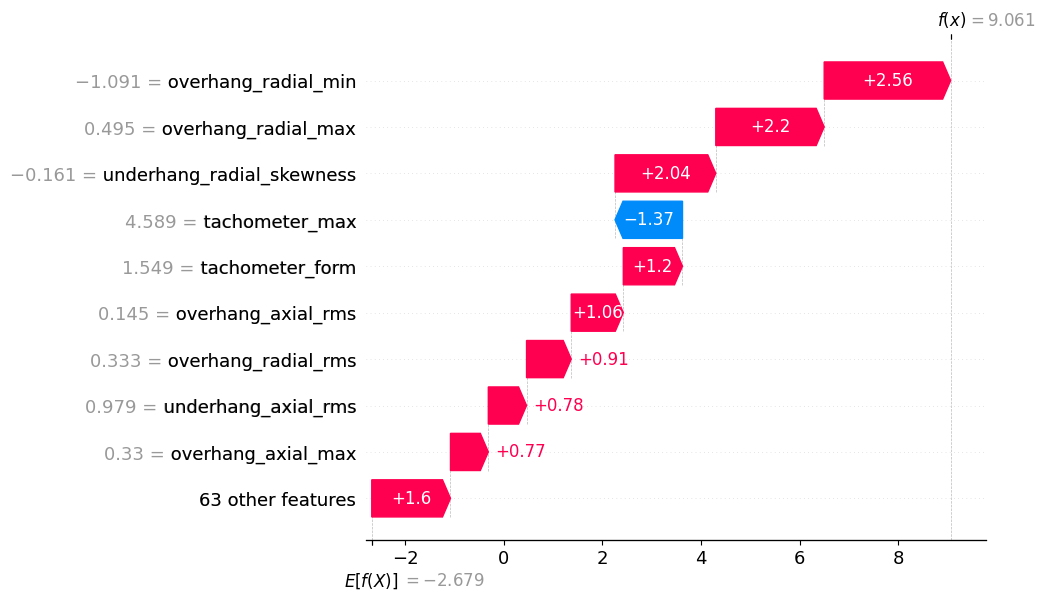


=== Sample 4 — True: normal, Predicted: imbalance ===


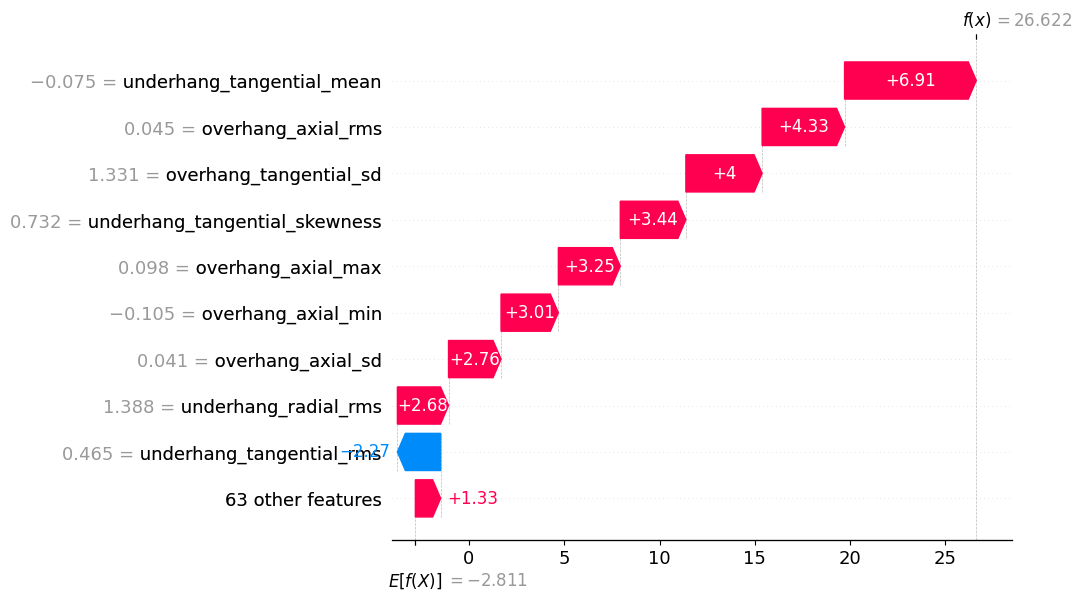

In [19]:
chosen_indices = [examples['normal'], examples['underhang_bearing'], examples['imbalance']]  # pick your 3

for idx in chosen_indices:
    pred_output = model(sample_to_explain[idx:idx+1]).detach().cpu().numpy()
    pred_class_idx = np.argmax(pred_output)
    
    print(f"\n=== Sample {idx} — True: {y_test.iloc[idx]}, Predicted: {le.classes_[pred_class_idx]} ===")
    
    shap_explanation = shap.Explanation(
        values=shap_values[idx, :, pred_class_idx],
        base_values=explainer.expected_value[pred_class_idx],
        data=X_test_sample_df.iloc[idx].values,
        feature_names=feature_cols
    )
    shap.plots.waterfall(shap_explanation, max_display=10)

In [21]:
samples = torch.tensor(
    X_test_scaled[:20],
    dtype=torch.float32
).to(device)

In [25]:
sample = samples[0].unsqueeze(0)

result = explain_prediction(
    model=model,
    explainer=explainer,
    sample_scaled=sample,
    feature_cols=X_train.columns,
    class_names=le.classes_
)

print(result)

{'predicted_class': 'normal', 'confidence': 0.9955386519432068, 'top_features': [{'feature': 'tachometer_max', 'contribution': 0.5780369639396667, 'direction': 'increases', 'meaning': 'Peak signal value — indicates strongest vibration spike — measured by: Rotation speed reference'}, {'feature': 'tachometer_mean', 'contribution': -0.5317670702934265, 'direction': 'decreases', 'meaning': 'Average signal level — shifts can indicate sensor bias or steady-state changes — measured by: Rotation speed reference'}, {'feature': 'underhang_axial_mean', 'contribution': -0.5109166502952576, 'direction': 'decreases', 'meaning': 'Average signal level — shifts can indicate sensor bias or steady-state changes — measured by: Vibration along shaft axis, motor-side bearing'}, {'feature': 'tachometer_form', 'contribution': -0.40583375096321106, 'direction': 'decreases', 'meaning': 'Waveform shape descriptor — measured by: Rotation speed reference'}, {'feature': 'tachometer_sd', 'contribution': 0.4035979807

In [26]:
report = explain_prediction(
    model=model,
    explainer=explainer,
    sample_scaled=samples[0].unsqueeze(0),
    feature_cols=X_train.columns,
    class_names=le.classes_
)

from pprint import pprint

pprint(report)

{'confidence': 0.9955386519432068,
 'engineering_explanation': '- tachometer_max (Peak signal value — indicates '
                            'strongest vibration spike — measured by: Rotation '
                            'speed reference) increases confidence in this '
                            'diagnosis\n'
                            '- tachometer_mean (Average signal level — shifts '
                            'can indicate sensor bias or steady-state changes '
                            '— measured by: Rotation speed reference) '
                            'decreases confidence in this diagnosis\n'
                            '- underhang_axial_mean (Average signal level — '
                            'shifts can indicate sensor bias or steady-state '
                            'changes — measured by: Vibration along shaft '
                            'axis, motor-side bearing) decreases confidence in '
                            'this diagnosis\n'
                      

In [1]:
import sys, os
current = os.getcwd()
while not os.path.exists(os.path.join(current, 'apps')) and current != os.path.dirname(current):
    current = os.path.dirname(current)
sys.path.append(current)

from apps.pipeline.diagnostic_pipeline import DiagnosticEngine
from apps.models.predictor import FaultPredictor

predictor = FaultPredictor()
background = predictor.scaler.transform(X_train.sample(100, random_state=42))

engine = DiagnosticEngine(background_data=background, feature_cols=feature_cols)

# structured dict output
result = engine.diagnose(X_test.iloc[0].to_dict())
import json
print(json.dumps(result, indent=2, default=str))

print("\n\n--- Formatted report ---\n")
# human-readable report
report = engine.diagnose(X_test.iloc[0].to_dict(), as_report=True)
print(report)

NameError: name 'X_train' is not defined